# Grover Operator / Amplitude Amplification — Qiskit Implementation

**Primitive:** 2-qubit Grover search, oracle marks |11>, one Grover iteration
`G = D * O` applied after the uniform-superposition state prep. With N = 4
basis states and M = 1 marked state, one iteration is exact: it drives the
success probability on |11> to 1.0 with zero shot noise in the ideal case.

**SETUP (must match the CUDA-Q notebook exactly for results to line up)**
- N QUBITS: 2
- GATES (shared source of truth, used for circuit build AND diagram):
  1. H on qubit 0            -- superposition prep
  2. H on qubit 1            -- superposition prep
  3. CZ, qubits (0, 1)       -- ORACLE: phase-flips |11> only
  4. H on qubit 0            -- diffusion, part 1
  5. H on qubit 1            -- diffusion, part 1
  6. X on qubit 0            -- diffusion, part 2
  7. X on qubit 1            -- diffusion, part 2
  8. CZ, qubits (0, 1)       -- diffusion's inversion-about-|00> phase flip
  9. X on qubit 0            -- diffusion, part 3
  10. X on qubit 1           -- diffusion, part 3
  11. H on qubit 0           -- diffusion, part 4
  12. H on qubit 1           -- diffusion, part 4
- QUBIT ORDERING CONTRACT: qubit 0 = rightmost bit in every printed bitstring
- SHOTS: 10000, SEED: 42
- GLOBAL PHASE: normalized so first nonzero amplitude (ascending bitstring order) is real and positive

**Theory recap:** Steps 1-2 build the uniform superposition
`|s> = (|00>+|01>+|10>+|11>)/2`. The oracle `O` (step 3) is a single CZ,
since flipping the phase of only `|11>` is exactly what a controlled-Z does
on a 2-qubit register -- no ancilla needed. The diffusion operator
`D = H(x)H . (2|00><00| - I) . H(x)H` is realized by steps 4-11:
sandwich an "inversion about |00>" (X, X, CZ, X, X -- which phase-flips
only `|00>`) between two layers of H. For N = 4, M = 1, the optimal number
of iterations is `round(pi/4 * sqrt(N/M)) = 1`, and this is one of the rare
cases where the amplification is exact: `sin^2(3*theta) = 1` for
`theta = arcsin(sqrt(1/4)) = pi/6`, so a single iteration should leave the
register in `|11>` with probability 1.0, no other outcomes possible even
before taking any shots.

H = 1/sqrt(2) * [[1, 1], [1, -1]]

X = [[0, 1], [1, 0]]

CZ(a, b): flips the sign of the amplitude iff both qubit a and qubit b are 1; symmetric in its two arguments.

**Bit-ordering note:** this notebook verifies qubit-0-rightmost empirically
in Section 1 with a calibration circuit before trusting any downstream
result, rather than assuming it.

**IMPORTANT: Run every cell in order, top to bottom** (Kernel -> Restart & Run All).

In [3]:
# Run this cell first if you get ModuleNotFoundError or MissingOptionalLibraryError.
# pylatexenc is required for circuit.draw(output="mpl") gate-label rendering.
!pip install -q qiskit qiskit-aer pylatexenc
# Restart the kernel after this finishes (Kernel -> Restart Kernel), then Run All.

In [4]:
# --- Imports ---
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

np.random.seed(42)

# --- SETUP constants ---
N_QUBITS = 2
SHOTS = 10000
SEED = 42

# GATES: shared source of truth for circuit build AND circuit diagram.
# Format: (gate_name, qubits_list, param).
#   "h":  qubits=[target]
#   "x":  qubits=[target]
#   "cz": qubits=[qubit_a, qubit_b]  (symmetric -- order doesn't affect the operation)
GATES = [
    ("h",  [0],    None),   # 1. superposition prep
    ("h",  [1],    None),   # 2. superposition prep
    ("cz", [0, 1], None),   # 3. ORACLE: marks |11>
    ("h",  [0],    None),   # 4. diffusion
    ("h",  [1],    None),   # 5. diffusion
    ("x",  [0],    None),   # 6. diffusion
    ("x",  [1],    None),   # 7. diffusion
    ("cz", [0, 1], None),   # 8. diffusion: inversion about |00>
    ("x",  [0],    None),   # 9. diffusion
    ("x",  [1],    None),   # 10. diffusion
    ("h",  [0],    None),   # 11. diffusion
    ("h",  [1],    None),   # 12. diffusion
]
print("Gate sequence:", GATES)
print(f"Total gates: {len(GATES)}")

Gate sequence: [('h', [0], None), ('h', [1], None), ('cz', [0, 1], None), ('h', [0], None), ('h', [1], None), ('x', [0], None), ('x', [1], None), ('cz', [0, 1], None), ('x', [0], None), ('x', [1], None), ('h', [0], None), ('h', [1], None)]
Total gates: 12


## 1. Bit-ordering calibration (verify, don't assume)

We apply X to the *highest-index* qubit only (qubit 1) and check which native statevector index lights up. Under the qubit-0-rightmost CONTRACT, the expected bitstring is `"10"` (leftmost char = qubit 1 = 1, the rest = 0). If Qiskit's native output already reads this way, no reversal is needed; if it reads reversed, `NEEDS_REVERSAL` is set True and used everywhere downstream instead of a hardcoded assumption.

In [5]:
calib_qc = QuantumCircuit(N_QUBITS)
calib_qc.x(N_QUBITS - 1)  # flip the highest-index qubit only, leave the rest at |0>
calib_sv = Statevector.from_instruction(calib_qc)

nonzero_idx = int(np.argmax(np.abs(calib_sv.data)))
native_bitstring = format(nonzero_idx, f"0{N_QUBITS}b")
expected_contract_bitstring = "1" + "0" * (N_QUBITS - 1)  # highest qubit = leftmost = 1, rest 0

if native_bitstring == expected_contract_bitstring:
    NEEDS_REVERSAL = False
elif native_bitstring[::-1] == expected_contract_bitstring:
    NEEDS_REVERSAL = True
else:
    raise RuntimeError(f"Calibration inconclusive: got '{native_bitstring}', "
                        f"expected '{expected_contract_bitstring}' or its reverse.")

print(f"Native bitstring for X(qubit {N_QUBITS-1}) only: '{native_bitstring}'")
print(f"Expected under contract (qubit0=rightmost):        '{expected_contract_bitstring}'")
print(f"NEEDS_REVERSAL = {NEEDS_REVERSAL}")

Native bitstring for X(qubit 1) only: '10'
Expected under contract (qubit0=rightmost):        '10'
NEEDS_REVERSAL = False


## 2. Build the circuit explicitly from the shared GATES list

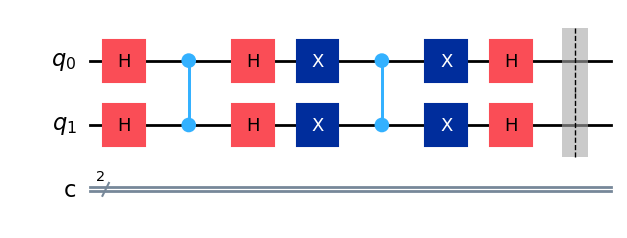

In [6]:
qc = QuantumCircuit(N_QUBITS, N_QUBITS, name="grover_operator")

for gate_name, qubits, param in GATES:
    if gate_name == "h":
        qc.h(qubits[0])
    elif gate_name == "x":
        qc.x(qubits[0])
    elif gate_name == "cz":
        qc.cz(qubits[0], qubits[1])
    else:
        raise ValueError(f"Unhandled gate in GATES: {gate_name}")

qc.barrier()
qc.draw(output="mpl")

## 3. Draw the circuit and save to file

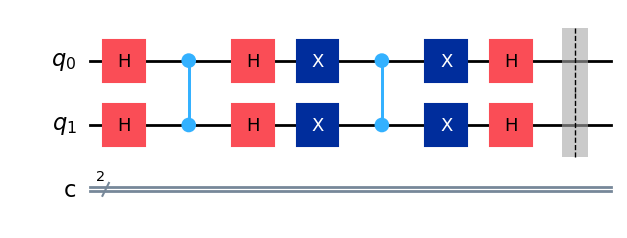

In [7]:
fig = qc.draw(output="mpl")
fig.savefig("grover_state_qiskit_circuit.png", bbox_inches="tight")
fig

## 4. Explicit matrix representation of the key operator(s)

In [8]:
H_matrix = (1 / np.sqrt(2)) * np.array([[1, 1],
                                          [1, -1]], dtype=complex)
X_matrix = np.array([[0, 1],
                      [1, 0]], dtype=complex)
print("H matrix:")
print(np.round(H_matrix, 4))
print()
print("X matrix:")
print(np.round(X_matrix, 4))
print()

def cz_matrix(qa, qb, n_qubits):
    """CZ matrix for arbitrary qubit pair in an n-qubit system, basis ordered
    with qubit 0 = rightmost (LSB) -- same convention as the GHZ-state notebook's
    cx_matrix, generalized to a diagonal phase-flip gate. CZ is symmetric in its
    two qubit arguments (order doesn't matter)."""
    dim = 2 ** n_qubits
    M = np.zeros((dim, dim), dtype=complex)
    for idx in range(dim):
        bits = [(idx >> k) & 1 for k in range(n_qubits)]  # bits[k] = qubit k value
        phase = -1.0 if (bits[qa] == 1 and bits[qb] == 1) else 1.0
        M[idx, idx] = phase
    return M

CZ01 = cz_matrix(0, 1, N_QUBITS)
print(f"CZ(0, 1) matrix, {2**N_QUBITS}x{2**N_QUBITS}, basis qubit0=rightmost:")
print(np.round(CZ01.real, 4))

H matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

X matrix:
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

CZ(0, 1) matrix, 4x4, basis qubit0=rightmost:
[[ 1.  0.  0.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0. -1.]]


In [9]:
def single_qubit_op_embedded(op, qubit, n_qubits):
    """Embed a 2x2 single-qubit operator into the full n-qubit space,
    with qubit 0 = rightmost/LSB (same tensor order as Qiskit's Statevector)."""
    mats = []
    for q in reversed(range(n_qubits)):
        mats.append(op if q == qubit else np.eye(2, dtype=complex))
    full = mats[0]
    for m in mats[1:]:
        full = np.kron(full, m)
    return full

H0 = single_qubit_op_embedded(H_matrix, 0, N_QUBITS)
H1 = single_qubit_op_embedded(H_matrix, 1, N_QUBITS)
X0 = single_qubit_op_embedded(X_matrix, 0, N_QUBITS)
X1 = single_qubit_op_embedded(X_matrix, 1, N_QUBITS)

GATE_MATRIX = {
    ("h", 0): H0, ("h", 1): H1,
    ("x", 0): X0, ("x", 1): X1,
    ("cz", (0, 1)): CZ01,
}

manual_full_op = np.eye(2 ** N_QUBITS, dtype=complex)
for gate_name, qubits, param in GATES:
    if gate_name == "cz":
        M = GATE_MATRIX[("cz", tuple(qubits))]
    else:
        M = GATE_MATRIX[(gate_name, qubits[0])]
    manual_full_op = M @ manual_full_op   # newest gate applied on the left

prep_circuit = QuantumCircuit(N_QUBITS, name="grover_op_only")
for gate_name, qubits, param in GATES:
    if gate_name == "h":
        prep_circuit.h(qubits[0])
    elif gate_name == "x":
        prep_circuit.x(qubits[0])
    elif gate_name == "cz":
        prep_circuit.cz(qubits[0], qubits[1])

full_op = Operator(prep_circuit)
print(f"Full {2**N_QUBITS}x{2**N_QUBITS} operator from Qiskit (basis qubit0=rightmost):")
print(np.round(full_op.data, 4))

assert np.allclose(full_op.data, manual_full_op, atol=1e-6), "Operator mismatch between Qiskit and manual construction!"
print()
print("Cross-check against manually constructed GATES-product operator: MATCH")

Full 4x4 operator from Qiskit (basis qubit0=rightmost):
[[ 0.+0.j  0.+0.j  0.+0.j  1.+0.j]
 [ 0.+0.j -1.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j -1.+0.j  0.+0.j]
 [-1.+0.j  0.+0.j  0.+0.j  0.+0.j]]

Cross-check against manually constructed GATES-product operator: MATCH


## 5. Exact statevector (before measurement), reordered if needed, global-phase normalized

In [10]:
sv = Statevector.from_instruction(qc)
amps = sv.data.copy()

def reorder_if_needed(amps, n_qubits, needs_reversal):
    if not needs_reversal:
        return amps.copy()
    dim = 2 ** n_qubits
    reordered = np.zeros(dim, dtype=complex)
    for native_idx in range(dim):
        native_bits = format(native_idx, f"0{n_qubits}b")
        target_bits = native_bits[::-1]
        target_idx = int(target_bits, 2)
        reordered[target_idx] = amps[native_idx]
    return reordered

def normalize_global_phase(statevector_data, n_qubits):
    dim = 2 ** n_qubits
    bitstrings = [format(i, f"0{n_qubits}b") for i in range(dim)]
    order = np.argsort(bitstrings)
    for idx in order:
        amp = statevector_data[idx]
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            corrected = statevector_data * np.exp(-1j * phase)
            return corrected, bitstrings
    return statevector_data, bitstrings

amps_contract = reorder_if_needed(amps, N_QUBITS, NEEDS_REVERSAL)
amps_norm, bitstrings = normalize_global_phase(amps_contract, N_QUBITS)

exact_probs = {}
for i, bs in enumerate(bitstrings):
    exact_probs[bs] = round(abs(amps_norm[i]) ** 2, 4)

exact_probs = dict(sorted(exact_probs.items()))
print("Exact statevector amplitudes (contract order, phase-normalized):")
print(np.round(amps_norm, 4))
print()
print("Exact statevector probabilities (qubit0 = rightmost):")
print(exact_probs)

Exact statevector amplitudes (contract order, phase-normalized):
[0.+0.j 0.+0.j 0.+0.j 1.+0.j]

Exact statevector probabilities (qubit0 = rightmost):
{'00': np.float64(0.0), '01': np.float64(0.0), '10': np.float64(0.0), '11': np.float64(1.0)}


## 6. Measurement: add measurements, run AerSimulator, plot histogram

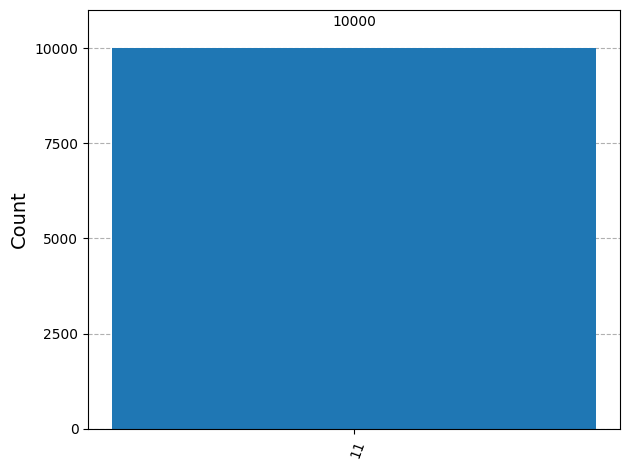

In [11]:
qc_measured = qc.copy()
qc_measured.measure(range(N_QUBITS), range(N_QUBITS))

sim = AerSimulator(seed_simulator=SEED)
job = sim.run(qc_measured, shots=SHOTS, seed_simulator=SEED)
result = job.result()
raw_counts = result.get_counts()

def reorder_counts_if_needed(counts, needs_reversal):
    if not needs_reversal:
        return dict(counts)
    out = {}
    for bs, c in counts.items():
        rbs = bs[::-1]
        out[rbs] = out.get(rbs, 0) + c
    return out

counts = reorder_counts_if_needed(raw_counts, NEEDS_REVERSAL)

fig2 = plot_histogram(counts)
fig2.savefig("grover_state_qiskit_histogram.png", bbox_inches="tight")
fig2

In [12]:
sampled_probs = {bs: round(c / SHOTS, 4) for bs, c in counts.items()}
sampled_probs = dict(sorted(sampled_probs.items()))
print(f"Sampled probabilities ({SHOTS} shots, seed={SEED}):")
print(sampled_probs)

Sampled probabilities (10000 shots, seed=42):
{'11': 1.0}


## 7. Circuit resource counts

In [13]:
print(f"Depth: {qc_measured.depth()}")
print(f"Gate/operation count: {qc_measured.size()}")
print(f"Gates in shared GATES spec: {len(GATES)}  (4x H prep+diffusion-outer + 2x CZ + 4x X, matches circuit build)")

Depth: 8
Gate/operation count: 14
Gates in shared GATES spec: 12  (4x H prep+diffusion-outer + 2x CZ + 4x X, matches circuit build)


## 8. Convention notes

In [14]:
print(f"Bit ordering: calibration in Section 1 found NEEDS_REVERSAL = {NEEDS_REVERSAL}.")
print("For Qiskit, Statevector/get_counts() natively index qubit 0 as the rightmost")
print("(least-significant) bit, which already matches the qubit0=rightmost CONTRACT --")
print("so no reversal was needed, confirmed empirically rather than assumed.")
print()
print("Global phase: normalized by finding the first nonzero amplitude in ascending-bitstring")
print("order and rotating the whole statevector so that amplitude becomes real and positive.")
print("For this primitive, the ideal circuit leaves exactly one nonzero amplitude (|11>), so")
print("this normalization rotates that single amplitude to +1 regardless of its raw sign/phase.")

Bit ordering: calibration in Section 1 found NEEDS_REVERSAL = False.
For Qiskit, Statevector/get_counts() natively index qubit 0 as the rightmost
(least-significant) bit, which already matches the qubit0=rightmost CONTRACT --
so no reversal was needed, confirmed empirically rather than assumed.

Global phase: normalized by finding the first nonzero amplitude in ascending-bitstring
order and rotating the whole statevector so that amplitude becomes real and positive.
For this primitive, the ideal circuit leaves exactly one nonzero amplitude (|11>), so
this normalization rotates that single amplitude to +1 regardless of its raw sign/phase.


## 9. Hand-derived expected result (independent sanity check)

Derived directly from the gate definitions, independent of the code above: with N = 4 basis states and M = 1 marked state (`|11>`), the optimal number of Grover iterations is `round((pi/4)*sqrt(N/M)) = 1`. Writing `theta = arcsin(sqrt(M/N)) = arcsin(1/2) = pi/6`, the success probability after k iterations is `sin^2((2k+1)*theta)`; for k = 1 that's `sin^2(3*pi/6) = sin^2(pi/2) = 1`. So a single iteration should leave the register in `|11>` with probability exactly 1.0, and every other bitstring at probability 0 -- this is one of the special cases where amplitude amplification is exact rather than approximate. Expected probabilities: `{'00': 0.0, '01': 0.0, '10': 0.0, '11': 1.0}`.

In [15]:
EXPECTED_PROBS = {format(i, f"0{N_QUBITS}b"): 0.0 for i in range(2 ** N_QUBITS)}
EXPECTED_PROBS["11"] = 1.0

max_delta_vs_hand = max(abs(exact_probs.get(k, 0) - EXPECTED_PROBS.get(k, 0))
                         for k in set(exact_probs) | set(EXPECTED_PROBS))
print("Max delta vs. hand-derived expectation:", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-6, "Computed result does not match hand-derived Grover-operator probabilities!"
print("Sanity check PASSED: exact_probs matches the hand-derived expectation.")

Max delta vs. hand-derived expectation: 0.0
Sanity check PASSED: exact_probs matches the hand-derived expectation.


## Final result (for diffing against the CUDA-Q version)

In [16]:
QISKIT_RESULT = exact_probs
print("QISKIT_RESULT =", QISKIT_RESULT)

QISKIT_RESULT = {'00': np.float64(0.0), '01': np.float64(0.0), '10': np.float64(0.0), '11': np.float64(1.0)}


## 10. Diff check against CUDA-Q

Paste the `CUDAQ_RESULT` dict printed at the end of the CUDA-Q notebook below, then run this cell.

In [17]:
CUDAQ_RESULT = {'00': 0.0, '01': 0.0, '10': 0.0, '11': 1.0}  # <-- paste from the CUDA-Q notebook's printed output

all_keys = sorted(set(QISKIT_RESULT) | set(CUDAQ_RESULT))
max_delta = max(abs(QISKIT_RESULT.get(k, 0) - CUDAQ_RESULT.get(k, 0)) for k in all_keys)
print("Max probability delta:", max_delta)
print("Match within tolerance:", max_delta < 1e-3)
assert max_delta < 1e-3, "Qiskit and CUDA-Q results disagree beyond tolerance!"
print("PASS: Qiskit and CUDA-Q results agree.")

Max probability delta: 0.0
Match within tolerance: True
PASS: Qiskit and CUDA-Q results agree.
